In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [41]:
RAW_FILE = Path("N:\\Projects\\Wind_Energy_ML\\data\\raw\\150m_Map_Data_A_to_G.csv")
PROCESSED_DIR = Path("N:\\Projects\\Wind_Energy_ML\\data\\processed")

In [42]:
CHUNK_SIZE = 100_000
SAMPLE_PER_CHUNK = 2_000

rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

eda_samples = []

RAW_FILE = Path(r"N:\Projects\Wind_Energy_ML\data\raw\150m_Map_Data_A_to_G.csv")

if not RAW_FILE.exists():
    raise FileNotFoundError(f"CSV file not found: {RAW_FILE}")

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    sample = chunk.sample(
        n=min(SAMPLE_PER_CHUNK, len(chunk)),
        random_state=42
    )

    eda_samples.append(sample)

eda_sample = pd.concat(
    eda_samples,
    ignore_index=True
)

print("EDA sample shape:", eda_sample.shape)

EDA sample shape: (390000, 7)


In [43]:
eda_sample.shape

(390000, 7)

In [44]:
eda_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 390000 entries, 0 to 389999
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   longitude           390000 non-null  float64
 1   latitude            390000 non-null  float64
 2   wind_speed          390000 non-null  float64
 3   weibull_a           390000 non-null  float64
 4   weibull_k           390000 non-null  float64
 5   air_density         390000 non-null  float64
 6   wind_power_density  390000 non-null  float64
dtypes: float64(7)
memory usage: 20.8 MB


In [45]:
eda_sample.columns.tolist()

['longitude',
 'latitude',
 'wind_speed',
 'weibull_a',
 'weibull_k',
 'air_density',
 'wind_power_density']

In [46]:
rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

eda_sample = eda_sample.rename(columns=rename_map)

eda_sample.head()

,longitude,latitude,wind_speed,weibull_a,weibull_k,air_density,wind_power_density
0,69.0780,21.9700,7.1120,7.9800,2.8630,1.1570,300.2000
1,69.1060,23.5060,7.5720,8.5470,2.3040,1.1450,417.5500
2,68.5300,23.3860,7.3400,8.2310,2.9050,1.1590,327.7700
3,69.0820,23.7060,7.3310,8.2740,2.3130,1.1530,380.3700
4,69.1900,24.0860,7.6760,8.6550,2.4520,1.1530,417.2100


In [47]:
eda_sample.columns

Index(['longitude', 'latitude', 'wind_speed', 'weibull_a', 'weibull_k',
       'air_density', 'wind_power_density'],
      dtype='str')

In [48]:
missing = eda_sample.isna().sum()

missing

longitude             0
latitude              0
wind_speed            0
weibull_a             0
weibull_k             0
air_density           0
wind_power_density    0
dtype: int64

In [49]:
duplicate_hashes = set()
duplicate_row_count = 0

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    row_hashes = pd.util.hash_pandas_object(
        chunk,
        index=False
    )

    for h in row_hashes:
        h = int(h)

        if h in duplicate_hashes:
            duplicate_row_count += 1
        else:
            duplicate_hashes.add(h)

print("Full-dataset duplicate rows:", duplicate_row_count)

Full-dataset duplicate rows: 0


In [50]:
# ============================================
# FULL DATASET DUPLICATE COORDINATE CHECK
# ============================================

coordinate_set = set()
duplicate_coordinate_count = 0

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    coordinates = zip(
        chunk["longitude"],
        chunk["latitude"]
    )

    for coord in coordinates:

        if coord in coordinate_set:
            duplicate_coordinate_count += 1
        else:
            coordinate_set.add(coord)

print(
    "Full-dataset duplicate coordinate pairs:",
    duplicate_coordinate_count
)

Full-dataset duplicate coordinate pairs: 0


In [51]:
print("Longitude range:",
      eda_sample["longitude"].min(),
      eda_sample["longitude"].max())

print("Latitude range:",
      eda_sample["latitude"].min(),
      eda_sample["latitude"].max())

Longitude range: 68.078 97.458
Latitude range: 6.566 37.134


In [52]:
# ============================================
# FULL DATASET COORDINATE VALIDATION
# ============================================

invalid_latitude = 0
invalid_longitude = 0

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    invalid_latitude += (
        ~chunk["latitude"].between(-90, 90)
    ).sum()

    invalid_longitude += (
        ~chunk["longitude"].between(-180, 180)
    ).sum()

print("Invalid latitude:", invalid_latitude)
print("Invalid longitude:", invalid_longitude)

Invalid latitude: 0
Invalid longitude: 0


In [53]:
eda_sample.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"390,000.0000",79.7296,6.1743,68.0780,75.4500,78.3180,82.7300,97.4580
latitude,"390,000.0000",23.1768,6.1965,6.5660,19.3220,23.6500,27.0500,37.1340
wind_speed,"390,000.0000",5.0789,1.3676,0.6210,4.2880,5.0370,5.9040,13.2710
weibull_a,"390,000.0000",5.6789,1.5605,0.6910,4.7770,5.6370,6.6320,14.7170
weibull_k,"390,000.0000",1.7478,0.3020,0.7470,1.5730,1.7120,1.8940,3.2040
air_density,"390,000.0000",1.0826,0.1118,0.5730,1.0890,1.1190,1.1420,1.1700
wind_power_density,"390,000.0000",182.1810,130.0637,0.3280,106.9400,161.5800,235.1800,"5,293.3000"


In [54]:
numeric_columns = [
    "wind_speed",
    "weibull_a",
    "weibull_k",
    "air_density",
    "wind_power_density"
]

for col in numeric_columns:
    print(f"\n{col}")
    print("Min :", eda_sample[col].min())
    print("Max :", eda_sample[col].max())


wind_speed
Min : 0.621
Max : 13.271

weibull_a
Min : 0.691
Max : 14.717

weibull_k
Min : 0.747
Max : 3.204

air_density
Min : 0.573
Max : 1.17

wind_power_density
Min : 0.328
Max : 5293.3


In [55]:
# ============================================
# FULL DATASET PHYSICAL VALIDATION
# ============================================

physical_issues = {
    "negative_wind_speed": 0,
    "invalid_weibull_a": 0,
    "invalid_weibull_k": 0,
    "invalid_air_density": 0,
    "negative_wind_power_density": 0
}

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    physical_issues["negative_wind_speed"] += (
        chunk["wind_speed"] < 0
    ).sum()

    physical_issues["invalid_weibull_a"] += (
        chunk["weibull_a"] <= 0
    ).sum()

    physical_issues["invalid_weibull_k"] += (
        chunk["weibull_k"] <= 0
    ).sum()

    physical_issues["invalid_air_density"] += (
        chunk["air_density"] <= 0
    ).sum()

    physical_issues["negative_wind_power_density"] += (
        chunk["wind_power_density"] < 0
    ).sum()

physical_issues

{'negative_wind_speed': np.int64(0),
 'invalid_weibull_a': np.int64(0),
 'invalid_weibull_k': np.int64(0),
 'invalid_air_density': np.int64(0),
 'negative_wind_power_density': np.int64(0)}

In [56]:
quality_report = pd.DataFrame(index=eda_sample.columns)

quality_report["dtype"] = eda_sample.dtypes.astype(str)
quality_report["missing_count"] = eda_sample.isna().sum()
quality_report["missing_pct"] = (
    eda_sample.isna().mean() * 100
)
quality_report["unique_values"] = eda_sample.nunique()
quality_report["min"] = eda_sample.min(numeric_only=True)
quality_report["max"] = eda_sample.max(numeric_only=True)

quality_report

,dtype,missing_count,missing_pct,unique_values,min,max
longitude,float64,0,0.0000,7338,68.0780,97.4580
latitude,float64,0,0.0000,7610,6.5660,37.1340
wind_speed,float64,0,0.0000,9820,0.6210,13.2710
weibull_a,float64,0,0.0000,10921,0.6910,14.7170
weibull_k,float64,0,0.0000,2293,0.7470,3.2040
air_density,float64,0,0.0000,580,0.5730,1.1700
wind_power_density,float64,0,0.0000,95723,0.3280,"5,293.3000"


In [57]:
def iqr_outlier_summary(df_in, columns):
    results = []

    for col in columns:
        q1 = df_in[col].quantile(0.25)
        q3 = df_in[col].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = ((df_in[col] < lower) | (df_in[col] > upper)).sum()

        results.append({
            "feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": count,
            "outlier_percentage": count / len(df_in) * 100
        })

    return pd.DataFrame(results)

outlier_report = iqr_outlier_summary(
    eda_sample,
    numeric_columns
)
print("Representative EDA Sample — IQR Outlier Analysis")
outlier_report

Representative EDA Sample — IQR Outlier Analysis


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,wind_speed,4.2880,5.9040,1.6160,1.8640,8.3280,11615,2.9782
1,weibull_a,4.7770,6.6320,1.8550,1.9945,9.4145,11078,2.8405
2,weibull_k,1.5730,1.8940,0.3210,1.0915,2.3755,17807,4.5659
3,air_density,1.0890,1.1420,0.0530,1.0095,1.2215,46414,11.9010
4,wind_power_density,106.9400,235.1800,128.2400,-85.4200,427.5400,11670,2.9923


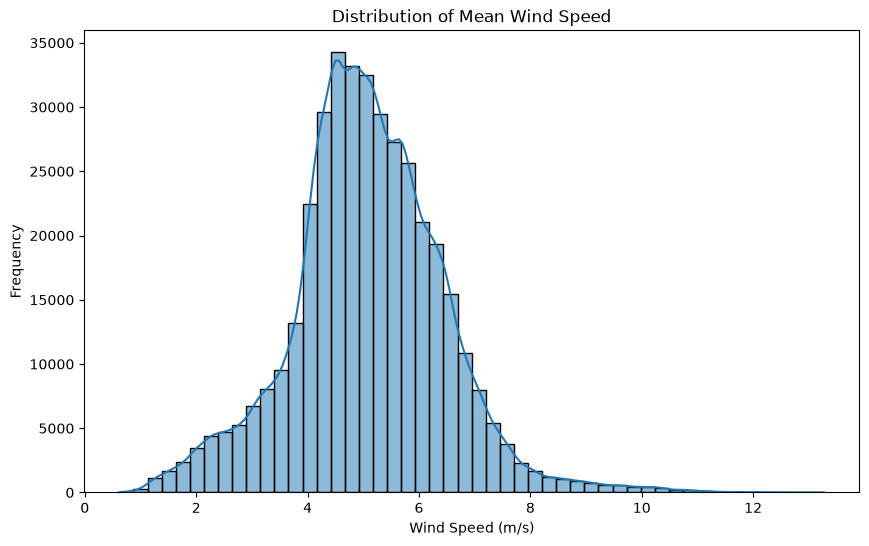

In [58]:
plt.figure(figsize=(10, 6))

sns.histplot(
    eda_sample["wind_speed"],
    bins=50,
    kde=True
)

plt.title("Distribution of Mean Wind Speed")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")

plt.show()

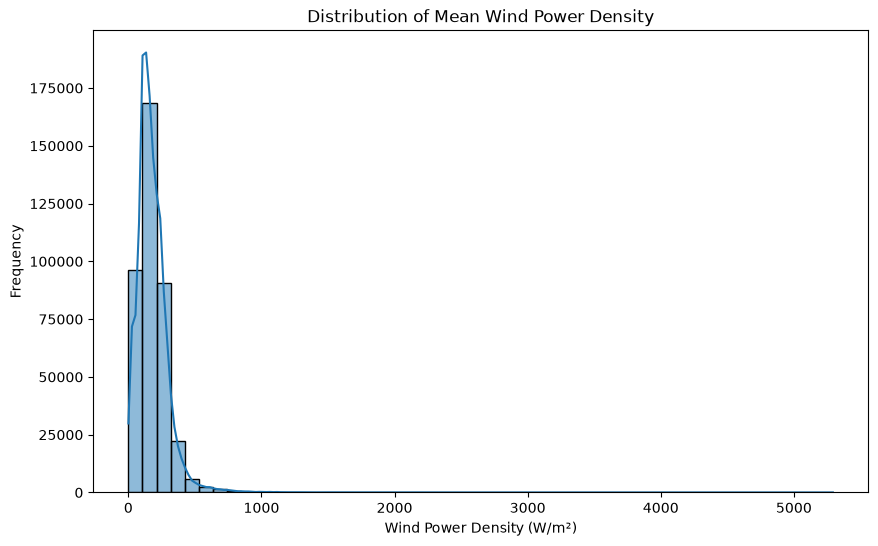

In [59]:
plt.figure(figsize=(10, 6))

sns.histplot(
    eda_sample["wind_power_density"],
    bins=50,
    kde=True
)

plt.title("Distribution of Mean Wind Power Density")
plt.xlabel("Wind Power Density (W/m²)")
plt.ylabel("Frequency")

plt.show()

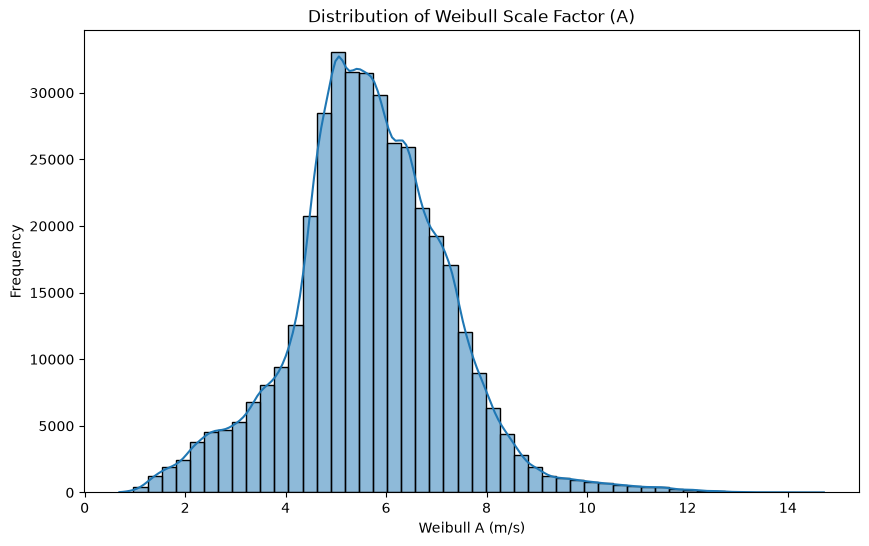

In [60]:
plt.figure(figsize=(10, 6))

sns.histplot(
    eda_sample["weibull_a"],
    bins=50,
    kde=True
)

plt.title("Distribution of Weibull Scale Factor (A)")
plt.xlabel("Weibull A (m/s)")
plt.ylabel("Frequency")

plt.show()

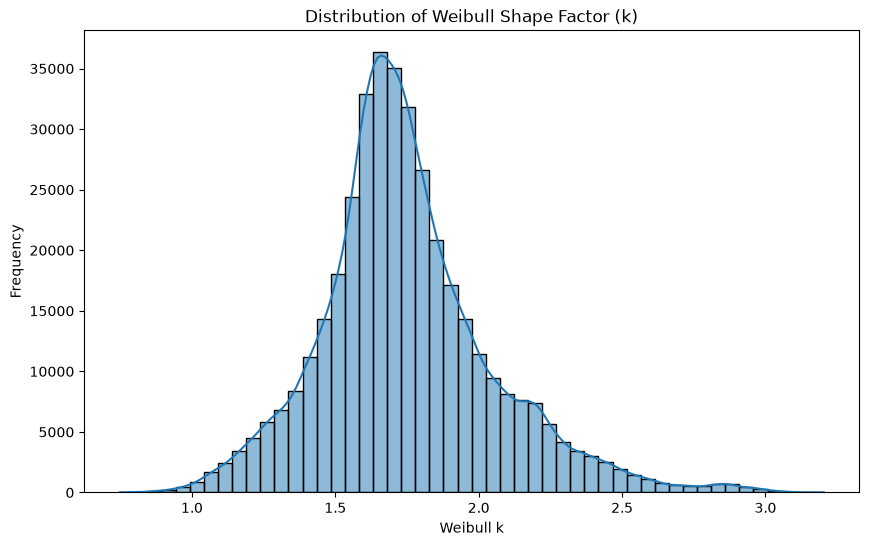

In [61]:
plt.figure(figsize=(10, 6))

sns.histplot(
    eda_sample["weibull_k"],
    bins=50,
    kde=True
)

plt.title("Distribution of Weibull Shape Factor (k)")
plt.xlabel("Weibull k")
plt.ylabel("Frequency")

plt.show()

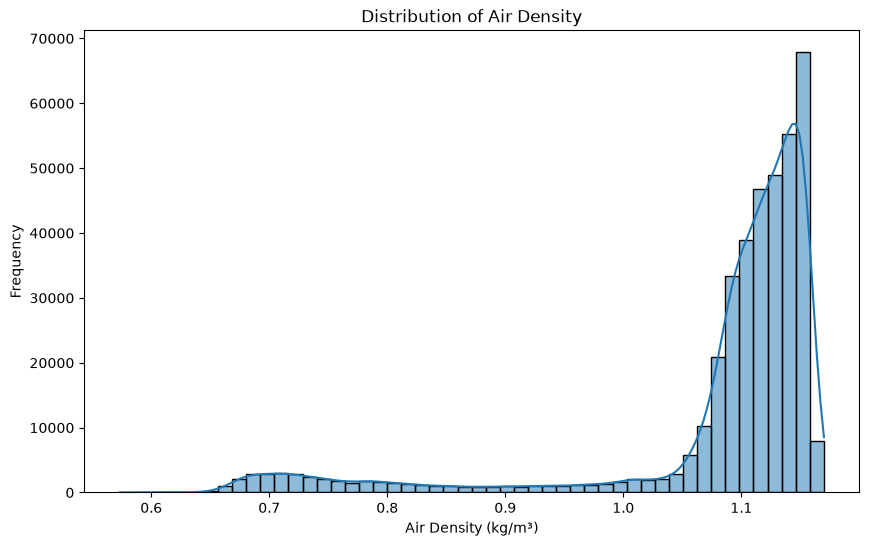

In [62]:
plt.figure(figsize=(10, 6))

sns.histplot(
    eda_sample["air_density"],
    bins=50,
    kde=True
)

plt.title("Distribution of Air Density")
plt.xlabel("Air Density (kg/m³)")
plt.ylabel("Frequency")

plt.show()

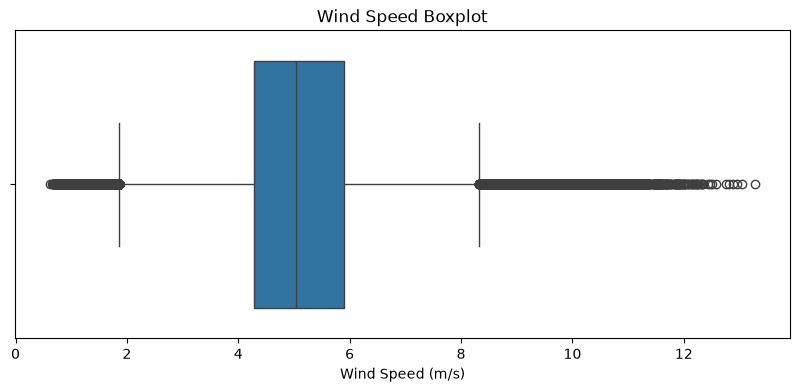

In [63]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=eda_sample["wind_speed"]
)

plt.title("Wind Speed Boxplot")
plt.xlabel("Wind Speed (m/s)")

plt.show()

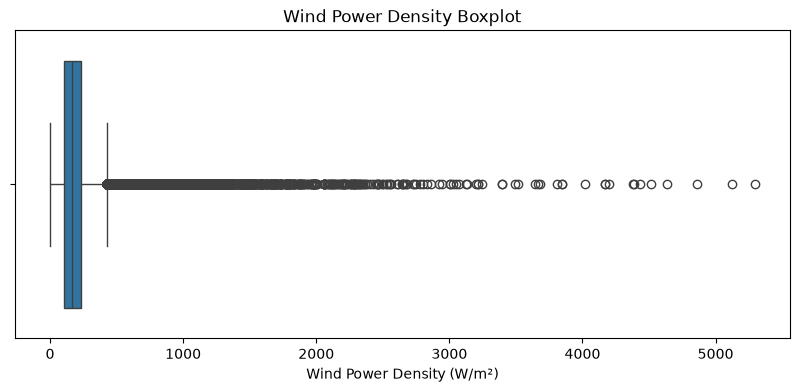

In [64]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=eda_sample["wind_power_density"]
)

plt.title("Wind Power Density Boxplot")
plt.xlabel("Wind Power Density (W/m²)")

plt.show()

In [65]:
corr = eda_sample[
    numeric_columns
].corr()

corr

,wind_speed,weibull_a,weibull_k,air_density,wind_power_density
wind_speed,1.0000,0.9989,0.6339,-0.1236,0.8484
weibull_a,0.9989,1.0000,0.6585,-0.1084,0.8318
weibull_k,0.6339,0.6585,1.0000,0.1950,0.3407
air_density,-0.1236,-0.1084,0.1950,1.0000,-0.1359
wind_power_density,0.8484,0.8318,0.3407,-0.1359,1.0000


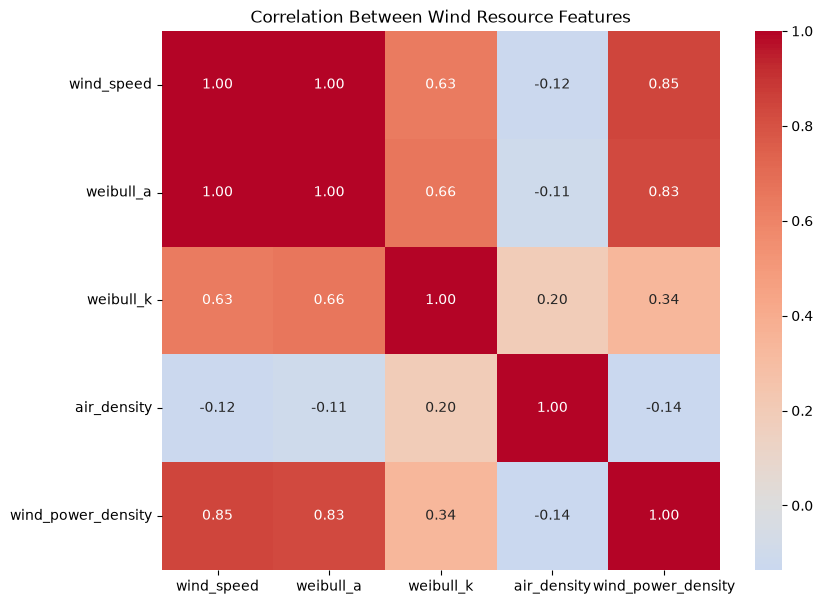

In [66]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Wind Resource Features")

plt.show()

EDA Finding: Wind speed, Weibull scale parameter, and wind power density exhibit strong positive correlations. This indicates substantial redundancy among wind-resource variables. PCA will therefore be used in the subsequent modeling stage to examine the underlying feature variance before clustering.

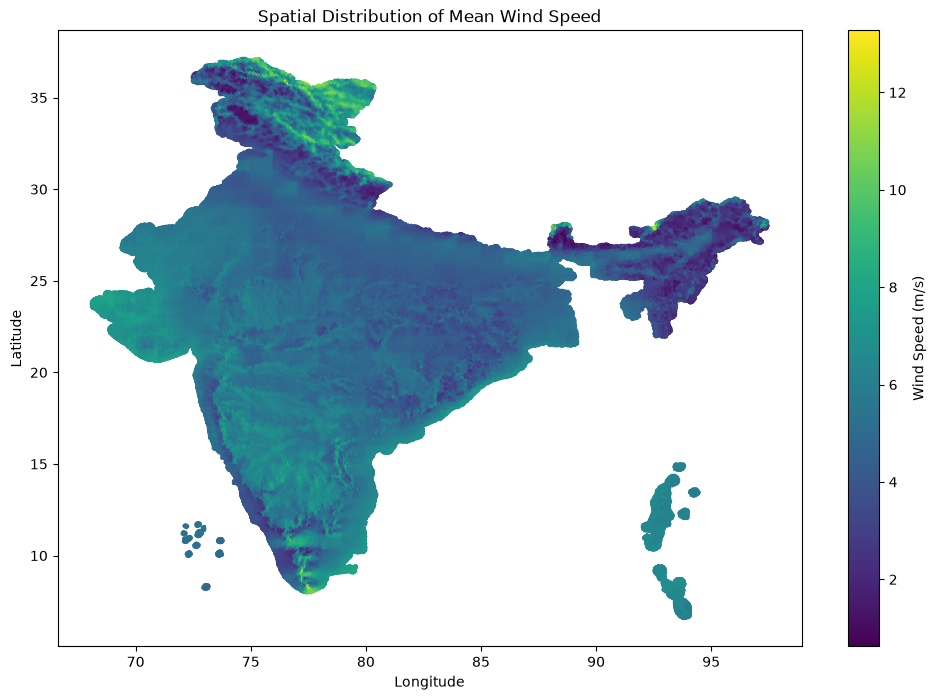

In [67]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    eda_sample["longitude"],
    eda_sample["latitude"],
    c=eda_sample["wind_speed"],
    s=2,
    cmap="viridis"
)

plt.colorbar(
    scatter,
    label="Wind Speed (m/s)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Spatial Distribution of Mean Wind Speed"
)

plt.show()

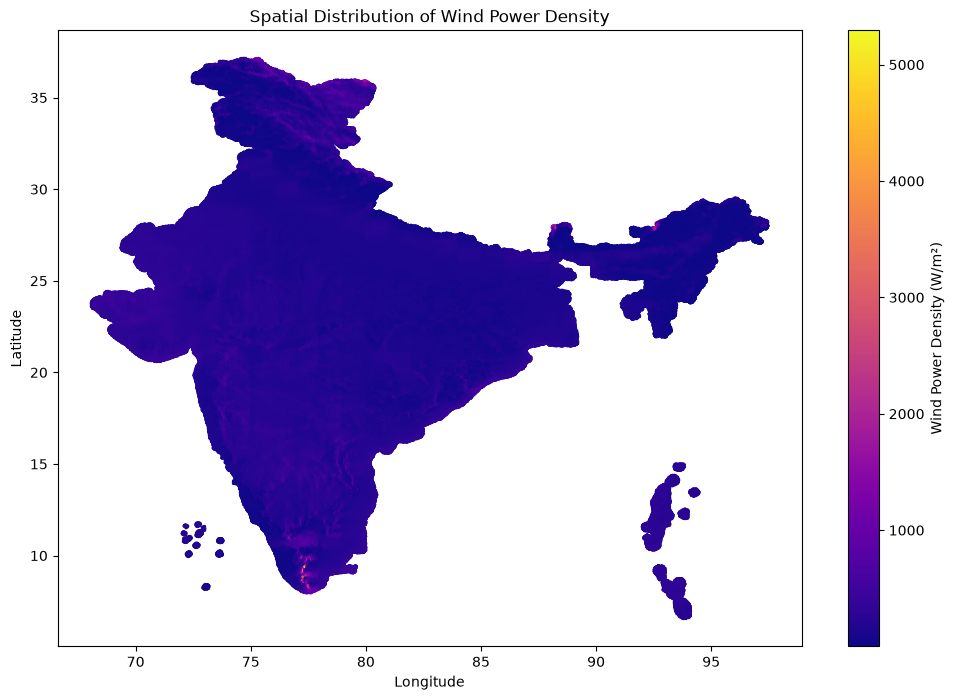

In [68]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    eda_sample["longitude"],
    eda_sample["latitude"],
    c=eda_sample["wind_power_density"],
    s=2,
    cmap="plasma"
)

plt.colorbar(
    scatter,
    label="Wind Power Density (W/m²)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Spatial Distribution of Wind Power Density"
)

plt.show()

In [69]:
plot_sample = eda_sample.sample(
    n=min(100000, len(eda_sample)),
    random_state=42
)

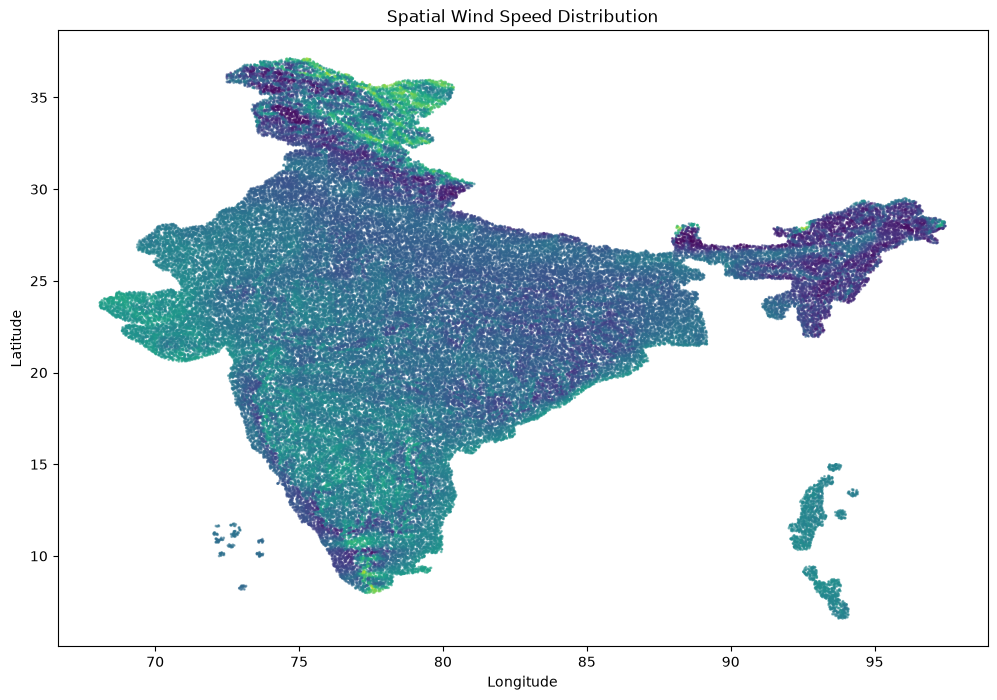

In [70]:
plt.figure(figsize=(12, 8))

plt.scatter(
    plot_sample["longitude"],
    plot_sample["latitude"],
    c=plot_sample["wind_speed"],
    s=1,
    alpha=0.5,
    cmap="viridis"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Wind Speed Distribution")

plt.show()

In [71]:
lon_diff = (
    eda_sample["longitude"]
    .sort_values()
    .drop_duplicates()
    .diff()
    .dropna()
)

lon_diff.describe()

count   7,337.0000
mean        0.0040
std         0.0001
min         0.0040
25%         0.0040
50%         0.0040
75%         0.0040
max         0.0080
Name: longitude, dtype: float64

In [72]:
lat_diff = (
    eda_sample["latitude"]
    .sort_values()
    .drop_duplicates()
    .diff()
    .dropna()
)

lat_diff.describe()

count   7,609.0000
mean        0.0040
std         0.0003
min         0.0040
25%         0.0040
50%         0.0040
75%         0.0040
max         0.0160
Name: latitude, dtype: float64

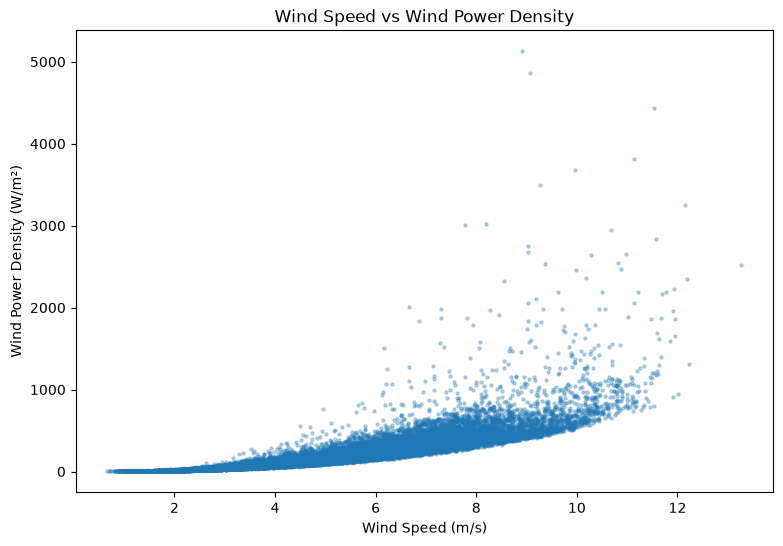

In [73]:
plt.figure(figsize=(9, 6))

plt.scatter(
    plot_sample["wind_speed"],
    plot_sample["wind_power_density"],
    s=5,
    alpha=0.3
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Wind Power Density (W/m²)")

plt.title(
    "Wind Speed vs Wind Power Density"
)

plt.show()

In [74]:
eda_sample[
    ["wind_speed", "wind_power_density"]
].corr()

,wind_speed,wind_power_density
wind_speed,1.0000,0.8484
wind_power_density,0.8484,1.0000


In [75]:
print("Representative EDA Sample Summary (390,000 observations)")
eda_sample_summary = pd.DataFrame({
    "Feature": numeric_columns,
    "Mean": [
        eda_sample[col].mean()
        for col in numeric_columns
    ],
    "Median": [
        eda_sample[col].median()
        for col in numeric_columns
    ],
    "Std Dev": [
        eda_sample[col].std()
        for col in numeric_columns
    ],
    "Minimum": [
        eda_sample[col].min()
        for col in numeric_columns
    ],
    "Maximum": [
        eda_sample[col].max()
        for col in numeric_columns
    ]
})

eda_sample_summary

Representative EDA Sample Summary (390,000 observations)


,Feature,Mean,Median,Std Dev,Minimum,Maximum
0,wind_speed,5.0789,5.0370,1.3676,0.6210,13.2710
1,weibull_a,5.6789,5.6370,1.5605,0.6910,14.7170
2,weibull_k,1.7478,1.7120,0.3020,0.7470,3.2040
3,air_density,1.0826,1.1190,0.1118,0.5730,1.1700
4,wind_power_density,182.1810,161.5800,130.0637,0.3280,"5,293.3000"


In [76]:
total_rows = 0

sum_values = pd.Series(
    0.0,
    index=numeric_columns
)

sum_squares = pd.Series(
    0.0,
    index=numeric_columns
)

count_values = pd.Series(
    0,
    index=numeric_columns
)

global_min = pd.Series(
    np.inf,
    index=numeric_columns
)

global_max = pd.Series(
    -np.inf,
    index=numeric_columns
)

for chunk in pd.read_csv(
    RAW_FILE,
    chunksize=CHUNK_SIZE
):

    chunk = chunk.rename(columns=rename_map)

    total_rows += len(chunk)

    data = chunk[numeric_columns]

    count_values += data.count()
    sum_values += data.sum()
    sum_squares += (data ** 2).sum()

    global_min = np.minimum(
        global_min,
        data.min()
    )

    global_max = np.maximum(
        global_max,
        data.max()
    )

In [77]:
mean_values = sum_values / count_values

variance = (
    sum_squares / count_values
    - mean_values ** 2
)

std_values = np.sqrt(
    variance
)

full_summary = pd.DataFrame({
    "count": count_values,
    "mean": mean_values,
    "std": std_values,
    "min": global_min,
    "max": global_max
})

print("Full Dataset Summary (19,475,568 observations)")
full_summary

Full Dataset Summary (19,475,568 observations)


,count,mean,std,min,max
wind_speed,19475568,5.0826,1.3661,0.5560,14.2370
weibull_a,19475568,5.6831,1.5588,0.6230,16.0530
weibull_k,19475568,1.7484,0.3019,0.7020,3.2080
air_density,19475568,1.0826,0.1121,0.5730,1.1710
wind_power_density,19475568,182.3059,129.9869,0.2040,"6,501.1000"


The NIWE 150 m wind-resource dataset contains 19,475,568 spatial observations covering the Indian region. Full-dataset chunk processing was used for data-quality validation and global descriptive statistics, while a representative sample of approximately 390,000 observations was used for visualization and exploratory analysis.

The dataset contains continuous spatial wind-resource variables including mean wind speed, Weibull parameters, air density, and wind power density. Strong positive correlations were observed among wind speed, Weibull scale factor, and wind power density, indicating potential feature redundancy.

Statistical outlier analysis identified extreme observations in several variables; these observations were retained because statistical extremeness does not necessarily indicate invalid geographical or meteorological conditions.

The spatial analysis confirms a predominantly regular coordinate grid and reveals substantial geographical variation in wind-resource characteristics across the study region.

These findings provide the foundation for integrating terrain-related variables and subsequently applying PCA, K-Means, and DBSCAN for wind-energy site suitability analysis.